# Twinkling stars and adaptive optics

Look at a bright star on a clear night: it twinkles, flickers in brightness
and sometimes in colour, while the planets shine steadily. Point a large
telescope at the same star and its image is not the Airy disk of the
aperture but a boiling cloud of speckles about an arcsecond wide, whatever
the size of the mirror. Both effects come from the same source:
**atmospheric turbulence**, a few kilometres of air whose refractive index
fluctuates by some 10⁻⁶ on scales from millimetres to tens of metres.

Kolmogorov's theory of turbulence makes all of this quantitative with one
number per layer, the Fried parameter $r_0$: the diameter over which the
wavefront from the star is still flat to about one radian. This notebook
builds a model atmosphere and checks it against the classical results:

1. **phase screens** with Kolmogorov and von Kármán statistics (FFT method
   plus subharmonics), their structure function and their Zernike content
   against Noll's variances,
2. a **vertical profile** of the turbulence, cut into layers: $r_0$, the
   seeing, the isoplanatic angle and the coherence time,
3. **twinkling**: a plane wave propagated through eight layers (split-step
   angular spectrum method), the scintillation index against Rytov theory,
   aperture averaging, light curves of an eye and a telescope, and why
   planets do not twinkle,
4. the **speckled star** in a 4 m telescope: short and long exposures, their
   transfer functions against Fried's formulas, and $r_0$ recovered from the
   images,
5. **lucky imaging**: Fried's probability of a nearly perfect short exposure,
   and a binary star that only the best frames resolve,
6. **adaptive optics**: a closed loop with a Shack-Hartmann sensor and a
   deformable mirror (zonal with 249 actuators, or modal with 119 Zernikes),
   the Strehl ratio over time, the corrected PSF and the error budget.

The new module `pyoptics.turbulence` holds the screens, the theory and the
frozen flow model; the propagation uses `propagators`, the wavefront sensor
`shack_hartmann`, the Zernikes `bases`, and the Strehl ratio follows the
definition of notebook 17 (`imaging.strehl_ratio()`: the peak of the PSF
relative to the unaberrated one).

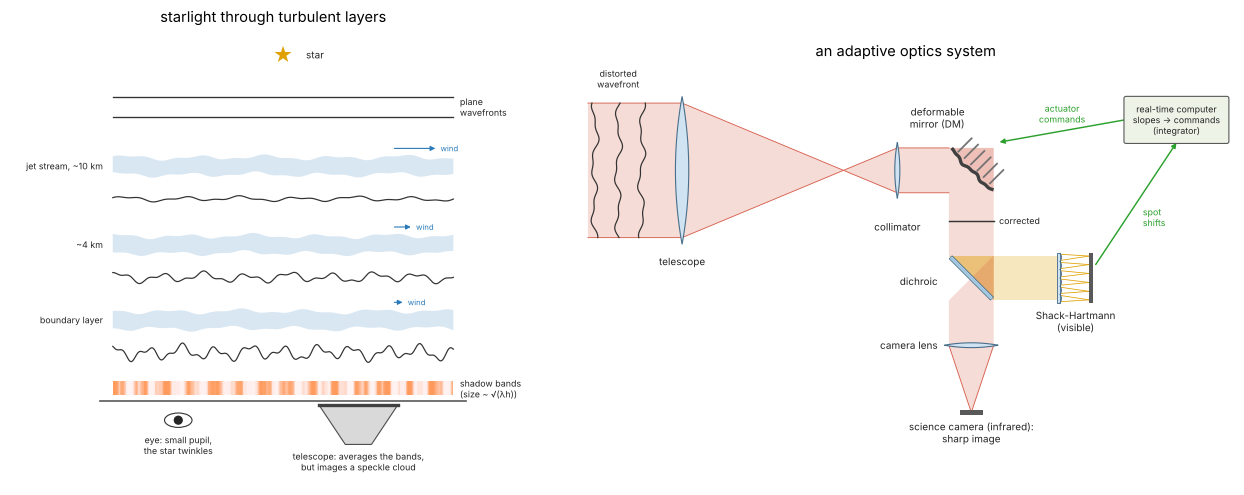

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap, LogNorm

from pyoptics import sketch, turbulence
from pyoptics.bases import fringe_zernike, fringe_to_n_m, fringe_zernike_norm
from pyoptics.fft import fft2, ifft2
from pyoptics.propagators import rayleigh_sommerfeld_I_TF
from pyoptics.shack_hartmann import ShackHartmann

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")         # magma_r, fading to white at zero
t_start = time.time()

WL0 = 0.5e-6                    # reference wavelength for r0 (m)
ARCSEC = np.pi/180/3600         # rad


def radial_mean(img, n_bins=None):
    """Azimuthal average of a centred image (centre at N//2), in pixels."""
    N = img.shape[0]
    iy, ix = np.indices(img.shape)
    r = np.hypot(ix - N//2, iy - N//2).astype(int)
    n_bins = N//2 if n_bins is None else n_bins
    s = np.bincount(r.ravel(), img.ravel(), minlength=n_bins)[:n_bins]
    c = np.bincount(r.ravel(), minlength=n_bins)[:n_bins]
    return s/np.maximum(c, 1)


def psf(pupil_field, pad):
    """Intensity PSF (centred) of a pupil field, zero padded to pad x pad."""
    N = pupil_field.shape[0]
    E = np.zeros((pad, pad), dtype=complex)
    E[:N, :N] = pupil_field
    return np.abs(np.fft.fftshift(fft2(E)))**2


fig, ax = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
sketch.twinkling_star(ax[0], title="starlight through turbulent layers")
sketch.adaptive_optics_system(ax[1], title="an adaptive optics system")
plt.tight_layout()

## 1. Kolmogorov phase screens

In the inertial range between the inner scale $l_0$ (millimetres) and the
outer scale $L_0$ (tens of metres) the refractive index fluctuations follow
Kolmogorov's two-thirds law with a strength $C_n^2$. A thin layer of
thickness $\delta h$ imprints on a passing wave the phase power spectrum

$$\Phi(f) = 0.0229\, r_0^{-5/3} \left(f^2 + L_0^{-2}\right)^{-11/6},\qquad
  r_0 = \left(0.423\,k^2 C_n^2\,\delta h\right)^{-3/5},$$

with $f$ in cycles per metre. Its structure function, the mean square phase
difference of two points a distance $r$ apart, is
$D(r) = 6.88\,(r/r_0)^{5/3}$ for $L_0 = \infty$; the von Kármán spectrum
with finite $L_0$ saturates at large $r$. Since $r_0 \propto k^{-6/5}$, the
Fried parameter grows with the wavelength as $\lambda^{6/5}$: 10 cm at
500 nm are 60 cm in the K band at 2.2 µm.

`turbulence.phase_screen()` filters white noise with $\sqrt{\Phi}$ in
Fourier space. A periodic grid of size $L$ only has the frequencies
$m/L$, and the steep spectrum puts most of the variance (the tilt) below
$1/L$. **Subharmonics** (Lane et al. 1992) add 3 × 3 grids of ever lower
frequencies, $1/(3L)$, $1/(9L)$, ..., around the origin; the module also
weights the lowest cells by their average over the cell instead of the
value at the centre. Below: the same random numbers without and with six
levels of subharmonics, and the structure functions averaged over 40
screens.

FFT only               r0 from D(r):  15.0 cm (true 10.0 cm)
3 subharmonic levels   r0 from D(r):  10.7 cm (true 10.0 cm)
6 subharmonic levels   r0 from D(r):   9.9 cm (true 10.0 cm)
D(dx)/theory = 0.93: the grid lacks all frequencies above Nyquist


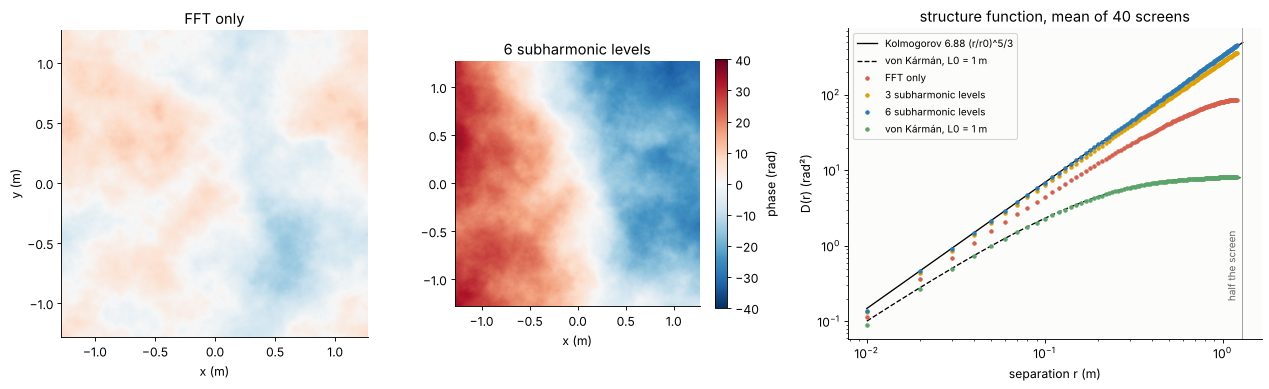

In [2]:
N_s, dx_s, r0_s = 256, 0.01, 0.10            # 2.56 m screens, 1 cm sampling, r0 = 10 cm
x_s = (np.arange(N_s) - N_s//2)*dx_s
cases = [("FFT only", dict(subharmonics=0)), ("3 subharmonic levels", dict(subharmonics=3)),
         ("6 subharmonic levels", dict(subharmonics=6)),
         ("von Kármán, L0 = 1 m", dict(subharmonics=6, L0=1.0))]
SF = {}
for name, kw in cases:
    screens = [turbulence.phase_screen(N_s, dx_s, r0_s, rng=i, **kw) for i in range(40)]
    r_sf, SF[name] = turbulence.structure_function(screens, dx_s, 120)
    if name in ("FFT only", "6 subharmonic levels"):
        SF[name + " screen"] = screens[0]

fig = plt.figure(figsize=(16, 5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.35])
for i, name in enumerate(["FFT only", "6 subharmonic levels"]):
    a = fig.add_subplot(gs[i])
    im = a.imshow(SF[name + " screen"], extent=[x_s[0], x_s[-1], x_s[0], x_s[-1]], cmap="RdBu_r",
                  vmin=-40, vmax=40)
    a.set_title(name)
    a.set_xlabel("x (m)")
    if i == 0:
        a.set_ylabel("y (m)")
plt.colorbar(im, ax=a, shrink=0.8, label="phase (rad)")
a = fig.add_subplot(gs[2])
r_th = np.geomspace(dx_s, 1.3, 200)
a.loglog(r_th, turbulence.structure_function_theory(r_th, r0_s), "k-", lw=1.2,
         label="Kolmogorov 6.88 (r/r0)^5/3")
a.loglog(r_th, turbulence.structure_function_theory(r_th, r0_s, 1.0), "k--", lw=1.2,
         label="von Kármán, L0 = 1 m")
for (name, _), c in zip(cases, ["#d6604d", "#e0a000", "#2a7ab9", "#5aa469"]):
    a.loglog(r_sf, SF[name], "o", ms=3, color=c, label=name)
a.axvline(N_s*dx_s/2, color="0.6", lw=0.8)
a.text(N_s*dx_s/2*0.95, 0.2, "half the screen", rotation=90, ha="right", fontsize=9, color="0.4")
a.set_xlabel("separation r (m)")
a.set_ylabel("D(r) (rad²)")
a.set_title("structure function, mean of 40 screens")
a.legend(fontsize=9)
plt.tight_layout()

# r0 from a fit of D = 6.88 (r/r0)^(5/3) between 2 cm and 0.6 m
sel = (r_sf >= 0.02) & (r_sf <= 0.6)
for name, _ in cases[:3]:
    r0_fit = np.exp(np.mean(np.log(r_sf[sel]) - 0.6*np.log(SF[name][sel]/turbulence.KOLMOGOROV_SF)))
    print("{:22s} r0 from D(r): {:5.1f} cm (true 10.0 cm)".format(name, 100*r0_fit))
print("D(dx)/theory = {:.2f}: the grid lacks all frequencies above Nyquist".format(
    SF["6 subharmonic levels"][0]/turbulence.structure_function_theory(dx_s, r0_s)))

The plain FFT screen lacks the large scales: its structure function bends
down long before half the screen size and $r_0$ comes out too large.
Three levels of subharmonics fix most of it, six follow $6.88\,(r/r_0)^{5/3}$
to within a few per cent up to half the screen. Only the first point,
$r = \Delta x$, stays some 7 % low, because the grid cannot hold the
frequencies above its Nyquist limit. With an outer scale of 1 m the
screens follow the von Kármán curve, which saturates at twice the phase
variance $0.173\,(L_0/r_0)^{5/3}$.

### Zernike modes of turbulence

Noll (1976) expanded Kolmogorov turbulence over a circular aperture of
diameter $D$ in Zernike polynomials. All modes of radial order $n$ have
the same variance, which falls steeply with $n$: the two tilts carry
0.449 $(D/r_0)^{5/3}$ rad² each, 87 % of the piston free variance
1.03 $(D/r_0)^{5/3}$. Correcting the first $J$ modes leaves the residual
$\Delta_J$, which for large $J$ falls as $0.2944\,J^{-\sqrt 3/2}(D/r_0)^{5/3}$.
`turbulence.noll_variance()` and `noll_residual()` hold these numbers.
Below, 150 screens are fitted with the Fringe Zernikes up to the radial
order 10 (66 modes, normalized to an RMS of 1 over the pupil) over a pupil
of $D = 10\,r_0$.

tilt variance: screens 0.423, Noll 0.449   (x (D/r0)^5/3)
piston removed: screens 1.002, theory 1.032;  tilt removed: 0.153 vs 0.135


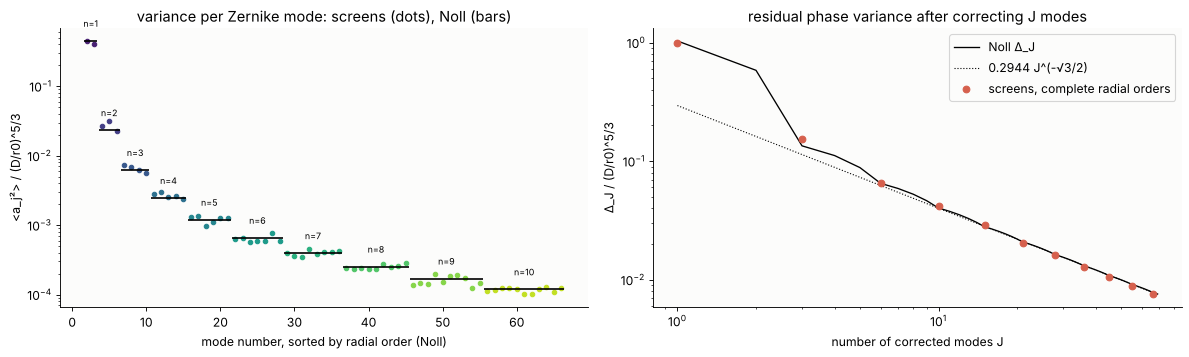

In [3]:
D_n, r0_n = 1.0, 0.1
n_pix = 128
dx_n = D_n/n_pix
xp = (np.arange(n_pix) - n_pix/2 + 0.5)*dx_n/(D_n/2)
PX, PY = np.meshgrid(xp, xp)
pupil_n = PX**2 + PY**2 <= 1
js = [j for j in range(1, 200) if fringe_to_n_m(j)[0] <= 10]
ns = np.array([fringe_to_n_m(j)[0] for j in js])
Zmat = np.array([fringe_zernike(j, PX[pupil_n], PY[pupil_n])/np.sqrt(fringe_zernike_norm(j)/np.pi)
                 for j in js]).T
coeffs = []
for i in range(150):
    phi = turbulence.phase_screen(256, dx_n, r0_n, rng=1000 + i)[64:192, 64:192]
    coeffs.append(np.linalg.lstsq(Zmat, phi[pupil_n], rcond=None)[0])
coeffs = np.array(coeffs)
var_j = coeffs.var(axis=0)
k53 = (D_n/r0_n)**(5/3)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
srt = np.argsort(ns, kind="stable")              # Noll order: by radial order
j_noll = np.arange(1, len(js) + 1)
for n in range(1, 11):
    sel = ns[srt] == n
    ax[0].semilogy(j_noll[sel], var_j[srt][sel]/k53, "o", ms=4, color=plt.cm.viridis(n/11))
    ax[0].hlines(turbulence.noll_variance(n), j_noll[sel].min() - 0.4, j_noll[sel].max() + 0.4,
                 color="k", lw=1.5)
    ax[0].text(j_noll[sel].mean(), 1.6*turbulence.noll_variance(n), "n={}".format(n),
               ha="center", fontsize=8)
ax[0].set_xlabel("mode number, sorted by radial order (Noll)")
ax[0].set_ylabel("<a_j²> / (D/r0)^5/3")
ax[0].set_title("variance per Zernike mode: screens (dots), Noll (bars)")
# residual after all modes up to radial order N, measured directly on the pupil
J_full, res_meas = [], []
for N_corr in range(0, 11):
    sel = ns <= N_corr
    A = Zmat[:, sel]
    res = []
    for i in range(0, 150, 3):
        phi = turbulence.phase_screen(256, dx_n, r0_n, rng=1000 + i)[64:192, 64:192][pupil_n]
        res.append(np.var(phi - A@np.linalg.lstsq(A, phi, rcond=None)[0]))
    J_full.append(np.count_nonzero(sel))
    res_meas.append(np.mean(res))
J_th = np.arange(1, 70)
ax[1].loglog(J_th, turbulence.noll_residual(J_th), "k-", lw=1.2, label="Noll Δ_J")
ax[1].loglog(J_th, 0.2944*J_th**(-np.sqrt(3)/2), "k:", lw=1, label="0.2944 J^(-√3/2)")
ax[1].loglog(J_full, np.array(res_meas)/k53, "o", color="#d6604d",
             label="screens, complete radial orders")
ax[1].set_xlabel("number of corrected modes J")
ax[1].set_ylabel("Δ_J / (D/r0)^5/3")
ax[1].set_title("residual phase variance after correcting J modes")
ax[1].legend()
plt.tight_layout()
print("tilt variance: screens {:.3f}, Noll {:.3f}   (x (D/r0)^5/3)".format(
    var_j[1:3].mean()/k53, turbulence.noll_variance(1)))
print("piston removed: screens {:.3f}, theory {:.3f};  tilt removed: {:.3f} vs {:.3f}".format(
    res_meas[0]/k53, turbulence.noll_residual(1), res_meas[1]/k53, turbulence.noll_residual(3)))

The screens reproduce Noll's numbers mode by mode, from the tilts down to
the tenth radial order, where the variance is a thousand times smaller,
within the scatter of 150 screens (some 10 % for the low orders, which
have few independent realizations per screen).
The residual curve is the basis of every adaptive optics design: a
Zernike corrector with $J$ modes leaves $\Delta_J (D/r_0)^{5/3}$, so the
number of modes needed grows roughly as $(D/r_0)^2$. The last points fall
a little below Noll's curve because the screens are sampled with 1 cm
pixels and lack the finest scales.

## 2. From a turbulence profile to layers

The turbulence is not spread evenly over the line of sight. Most of it
sits in the boundary layer near the ground and in thin sheets at the
tropopause, where the jet stream shears the air. The Hufnagel-Valley model

$$C_n^2(h) = 0.00594\,(v/27)^2 (10^{-5}h)^{10} e^{-h/1000} + 2.7\cdot 10^{-16}
  e^{-h/1500} + A\,e^{-h/100}$$

describes such a profile. With a moderate ground layer
($A = 2\cdot10^{-15}$ m$^{-2/3}$, $v = 15$ m/s) it gives a good site with
about one arcsecond of seeing. `turbulence.layers_from_profile()` cuts it
into eight slabs, each a thin phase screen at its $C_n^2$-weighted height.
The classical integrals then give

- the total Fried parameter $r_0 = (0.423\,k^2 \sum C_n^2\delta h)^{-3/5}$ and
  the seeing $0.976\,\lambda/r_0$,
- the **isoplanatic angle** $\theta_0 = (2.914\,k^2\sum C_n^2\delta h\,h^{5/3})^{-3/5}$,
  over which two stars see the same wavefront (to 1 rad²),
- the **coherence time** $\tau_0 = 0.314\,r_0/\bar v$, after which the
  wavefront has changed by 1 rad²,
- the **scintillation index** of a point detector (Rytov),
  $\sigma_I^2 = 19.12\,\lambda^{-7/6}\sum C_n^2\delta h\,h^{5/6}$.

Every layer gets a wind velocity, so that the screens can move (frozen
flow); the speeds are multiples of 5 m/s for the twinkling movies of
section 3.

total r0 = 10.2 cm at 500 nm, seeing 0.99" (FWHM)
with an outer scale of 25 m the seeing is 0.82" (Tokovinin)
isoplanatic angle 2.02", coherence time 2.9 ms, scintillation index 0.142
  J: r0 =  31 cm, theta0 = 6.1", tau0 =  8.7 ms
  H: r0 =  43 cm, theta0 = 8.5", tau0 = 12.1 ms
  K: r0 =  60 cm, theta0 = 12.0", tau0 = 17.1 ms


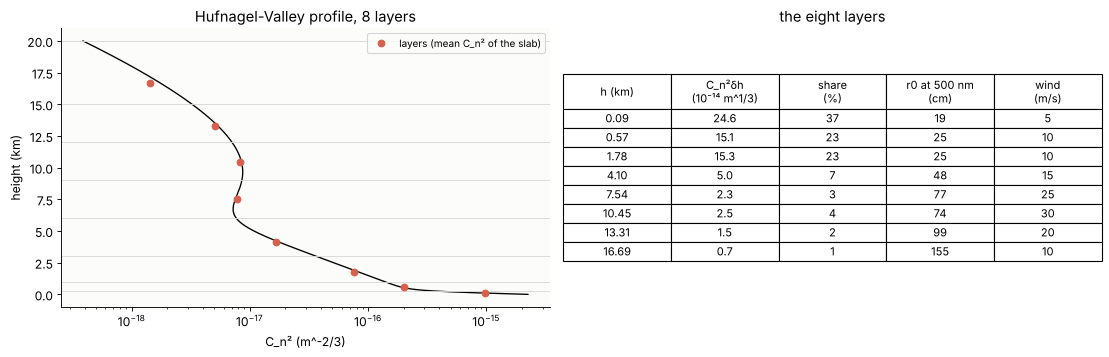

In [4]:
profile = lambda h: turbulence.hufnagel_valley(h, v_rms=15, A=2e-15)
edges = np.array([0, 250, 1000, 3000, 6000, 9000, 12000, 15000, 20000])
H, CN2 = turbulence.layers_from_profile(profile, edges)
SPEEDS = np.array([5, 10, 10, 15, 25, 30, 20, 10.])          # m/s
ANGLES = np.random.default_rng(1).uniform(0, 2*np.pi, len(H))
R0 = turbulence.fried_parameter(CN2, WL0)
THETA0 = turbulence.isoplanatic_angle(H, CN2, WL0)
TAU0 = turbulence.coherence_time(CN2, SPEEDS, WL0)
SIGMA_I2 = turbulence.scintillation_index(H, CN2, WL0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1, 1.1]))
hh = np.linspace(1, 20000, 4000)
ax[0].semilogx(profile(hh), hh/1e3, "k-", lw=1.2)
for a, b in zip(edges[:-1], edges[1:]):
    ax[0].axhline(b/1e3, color="0.85", lw=0.8)
ax[0].plot(CN2/np.diff(edges), H/1e3, "o", color="#d6604d", label="layers (mean C_n² of the slab)")
ax[0].set_xlabel("C_n² (m^-2/3)")
ax[0].set_ylabel("height (km)")
ax[0].set_title("Hufnagel-Valley profile, 8 layers")
ax[0].legend(loc="upper right", fontsize=9)
ax[1].axis("off")
rows = [["{:.2f}".format(h/1e3), "{:.1f}".format(1e14*c), "{:.0f}".format(100*CN2[i]/CN2.sum()),
         "{:.0f}".format(100*turbulence.fried_parameter(c, WL0)), "{:.0f}".format(v)]
        for i, (h, c, v) in enumerate(zip(H, CN2, SPEEDS))]
tab = ax[1].table(cellText=rows, colLabels=["h (km)", "C_n²δh\n(10⁻¹⁴ m^1/3)", "share\n(%)",
                                             "r0 at 500 nm\n(cm)", "wind\n(m/s)"],
                  loc="center", cellLoc="center")
tab.auto_set_font_size(False)
tab.set_fontsize(10)
tab.scale(1, 1.45)
for (r_, c_), cell in tab.get_celld().items():
    if r_ == 0:
        cell.set_height(cell.get_height()*1.8)
ax[1].set_title("the eight layers")
plt.tight_layout()
print("total r0 = {:.1f} cm at 500 nm, seeing {:.2f}\" (FWHM)".format(
    100*R0, turbulence.seeing_fwhm(R0, WL0)/ARCSEC))
print("with an outer scale of 25 m the seeing is {:.2f}\" (Tokovinin)".format(
    turbulence.seeing_fwhm(R0, WL0, L0=25)/ARCSEC))
print("isoplanatic angle {:.2f}\", coherence time {:.1f} ms, scintillation index {:.3f}".format(
    THETA0/ARCSEC, 1e3*TAU0, SIGMA_I2))
for band, wl in (("J", 1.25e-6), ("H", 1.65e-6), ("K", 2.2e-6)):
    print("  {}: r0 = {:3.0f} cm, theta0 = {:.1f}\", tau0 = {:4.1f} ms".format(
        band, 100*turbulence.r0_at_wavelength(R0, WL0, wl),
        turbulence.isoplanatic_angle(H, CN2, wl)/ARCSEC, 1e3*turbulence.coherence_time(CN2, SPEEDS, wl)))

The ground layer dominates $r_0$ (a third of the turbulence), but the
high layers, though weaker, dominate the isoplanatic angle and the
scintillation: both weight the layers with a power of their height. In
the infrared all three numbers become more comfortable, which is why
adaptive optics works best there.

## 3. Twinkling: scintillation from the layers

A phase screen alone does not change the intensity. But over the long way
down to the ground the corrugated wavefront focuses and defocuses the
light. In the weak fluctuation (Rytov) picture, a phase ripple of spatial
frequency $f$ at height $h$ turns into a log-amplitude ripple
$\chi$ with the Fresnel filter $\sin(\pi\lambda h f^2)$: ripples much
larger than the Fresnel scale $\sqrt{\lambda h}$ (7 cm for 10 km) hardly
show up in the intensity, ripples of about that size do. The intensity
pattern on the ground, the "shadow bands", therefore has a typical size
of a few centimetres, and moves with the winds.

Here the star is a plane wave at 500 nm that enters the top layer, picks
up its phase, is propagated (angular spectrum method,
`turbulence.split_step()`) to the next layer, and so on down to the
ground. The grid is 10.24 m wide with 5 mm sampling, and the screens are
periodic (no subharmonics): a periodic atmosphere keeps the propagation
exact without padding, and the large scales that the subharmonics would
add do not matter for the intensity.

scintillation index: simulation 0.142, Rytov theory 0.142 (point detector)


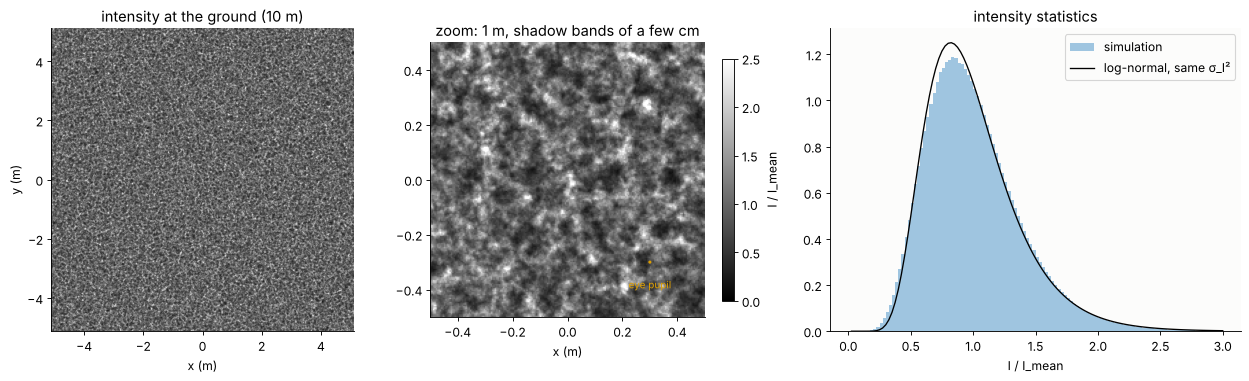

In [5]:
N_t, dx_t = 2048, 5e-3
x_t = (np.arange(N_t) - N_t//2)*dx_t
screens_t = [turbulence.phase_screen(N_t, dx_t, turbulence.fried_parameter(c, WL0),
                                     subharmonics=0, rng=10 + i) for i, c in enumerate(CN2)]
order = np.argsort(H)[::-1]                          # from the top down
h_sorted = H[order]
dists = np.append(h_sorted[:-1] - h_sorted[1:], h_sorted[-1])
u_ground = turbulence.split_step(np.ones((N_t, N_t)), x_t, x_t, [screens_t[i] for i in order],
                                 dists, WL0)
I_ground = np.abs(u_ground)**2
s2_sim = I_ground.var()/I_ground.mean()**2

fig, ax = plt.subplots(1, 3, figsize=(16, 4.9), gridspec_kw=dict(width_ratios=[1, 1, 1.2]))
im = ax[0].imshow(I_ground, extent=[x_t[0], x_t[-1], x_t[0], x_t[-1]], cmap="gray", vmin=0, vmax=2.5)
ax[0].set_title("intensity at the ground (10 m)")
ax[0].set_xlabel("x (m)"); ax[0].set_ylabel("y (m)")
z = slice(N_t//2 - 100, N_t//2 + 100)
ax[1].imshow(I_ground[z, z], extent=[-0.5, 0.5, -0.5, 0.5], cmap="gray", vmin=0, vmax=2.5)
ax[1].add_patch(plt.Circle((0.3, -0.3), 0.0035, color="#e0a000"))
ax[1].text(0.3, -0.36, "eye pupil", color="#e0a000", ha="center", va="top", fontsize=9)
ax[1].set_title("zoom: 1 m, shadow bands of a few cm")
ax[1].set_xlabel("x (m)")
plt.colorbar(im, ax=ax[1], shrink=0.8, label="I / I_mean")
bins = np.linspace(0, 3, 121)
ax[2].hist(I_ground.ravel(), bins=bins, density=True, color="#9fc5e0", label="simulation")
s_ln = np.sqrt(np.log(1 + s2_sim))
Ib = bins[1:]
ax[2].plot(Ib, np.exp(-(np.log(Ib) + s_ln**2/2)**2/(2*s_ln**2))/(Ib*s_ln*np.sqrt(2*np.pi)), "k-",
           lw=1.2, label="log-normal, same σ_I²")
ax[2].set_xlabel("I / I_mean")
ax[2].set_title("intensity statistics")
ax[2].legend()
plt.tight_layout()
print("scintillation index: simulation {:.3f}, Rytov theory {:.3f} (point detector)".format(
    s2_sim, SIGMA_I2))

The simulated scintillation index agrees with the Rytov integral, and the
intensity is close to log-normal, as weak scintillation should be.

### Aperture averaging: why a telescope sees less twinkling

A detector of diameter $D$ integrates the shadow bands over its area.
Once $D$ exceeds the Fresnel scale, many bands average out and the flux
fluctuates much less; for $D \gg \sqrt{\lambda h}$ the variance falls as
$D^{-7/3}$. `turbulence.scintillation_index(..., D=D)` includes the
aperture filter $[2J_1(\pi D f)/(\pi D f)]^2$ in the Rytov integral. The
simulation averages the ground intensity over disks of diameter $D$ at
all positions.

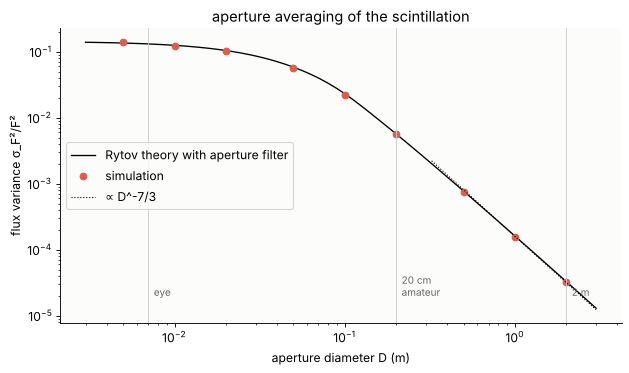

In [6]:
X_t, Y_t = np.meshgrid(x_t, x_t)
FI = fft2(I_ground)
Ds = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0])
s2_D = []
for D in Ds:
    disk = (X_t**2 + Y_t**2 <= (D/2)**2).astype(float)
    disk /= disk.sum()
    F = np.real(ifft2(FI*fft2(np.fft.ifftshift(disk))))
    s2_D.append(F.var()/F.mean()**2)
D_th = np.geomspace(0.003, 3, 60)
s2_th = [turbulence.scintillation_index(H, CN2, WL0, D=D) for D in D_th]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(D_th, s2_th, "k-", lw=1.2, label="Rytov theory with aperture filter")
ax.loglog(Ds, s2_D, "o", color="#d6604d", label="simulation")
ax.loglog(D_th[D_th > 0.3], 0.95*s2_th[-1]*(D_th[D_th > 0.3]/D_th[-1])**(-7/3), "k:", lw=1,
          label="∝ D^-7/3")
for D, name in ((0.007, "eye"), (0.2, "20 cm\namateur"), (2.0, "2 m")):
    ax.axvline(D, color="0.8", lw=0.8)
    ax.text(D*1.08, 2e-5, name, fontsize=9, color="0.4")
ax.set_xlabel("aperture diameter D (m)")
ax.set_ylabel("flux variance σ_F²/F²")
ax.set_title("aperture averaging of the scintillation")
ax.legend()
plt.tight_layout()

### Light curves and the colours of twinkling

How fast does a star twinkle? The layers move with their winds, and each
carries its shadow pattern along. In the weak fluctuation regime the
log-amplitudes of the layers simply add, $\chi = \sum_i \chi_i$, so each
layer is propagated to the ground once, alone, and its log-amplitude is
shifted with its wind (frozen flow) to get the intensity
$e^{2\chi(t)}$ at any time. A first check that this is allowed: the sum
of the eight single-layer patterns against the full split-step result.

correlation of exp(2 sum chi_i) with the split-step intensity: 0.937
scintillation index of the additive model: 0.148 (split step 0.142)


flux variance: eye 0.155, 1 m telescope 0.00019


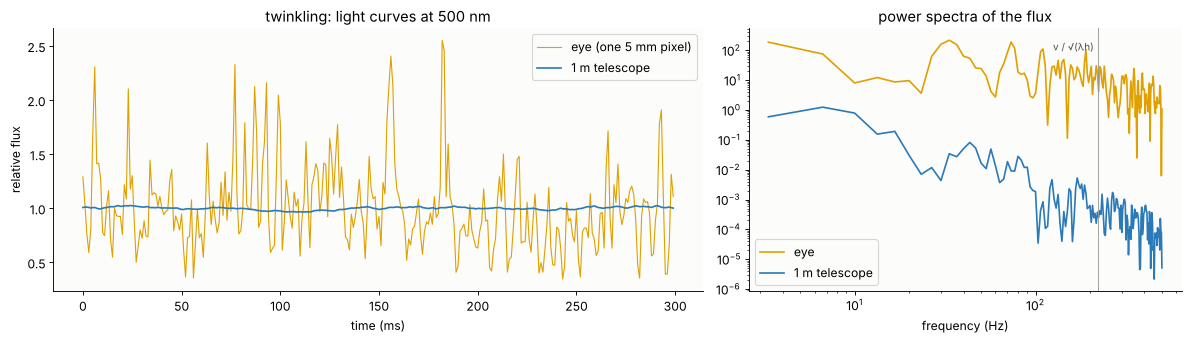

In [7]:
chi_layers = []
for i, c in enumerate(CN2):
    u1 = rayleigh_sommerfeld_I_TF(np.exp(1j*screens_t[i]), x_t, x_t, H[i], WL0)[0]
    chi_layers.append(np.log(np.abs(u1)))
chi_sum = np.sum(chi_layers, axis=0)
I_rytov = np.exp(2*chi_sum)
I_rytov /= I_rytov.mean()
print("correlation of exp(2 sum chi_i) with the split-step intensity: {:.3f}".format(
    np.corrcoef(I_rytov.ravel(), I_ground.ravel())[0, 1]))
print("scintillation index of the additive model: {:.3f} (split step {:.3f})".format(
    I_rytov.var(), s2_sim))

dt_lc = 1e-3                                   # 1 ms: every wind moves an integer number of pixels
steps = np.round(np.c_[SPEEDS*np.cos(ANGLES), SPEEDS*np.sin(ANGLES)]*dt_lc/dx_t).astype(int)
n_t = 300
w_half = 110                                   # window of 1.1 m around the origin
idx = np.arange(-w_half, w_half)
Xw, Yw = np.meshgrid(idx*dx_t, idx*dx_t)
tel = Xw**2 + Yw**2 <= 0.5**2                  # 1 m telescope


def chi_window(k):
    """Sum of the layer log-amplitudes on the window at time step k."""
    out = 0.0
    for i in range(len(H)):
        ry = (N_t//2 + idx - k*steps[i, 1]) % N_t
        rx = (N_t//2 + idx - k*steps[i, 0]) % N_t
        out = out + chi_layers[i][np.ix_(ry, rx)]
    return out


eye, telescope = [], []
for k in range(n_t):
    Iw = np.exp(2*chi_window(k))
    eye.append(Iw[w_half, w_half])
    telescope.append(Iw[tel].mean())
eye, telescope = np.array(eye)/np.mean(eye), np.array(telescope)/np.mean(telescope)
t_lc = np.arange(n_t)*dt_lc

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax[0].plot(1e3*t_lc, eye, color="#e0a000", lw=1, label="eye (one 5 mm pixel)")
ax[0].plot(1e3*t_lc, telescope, color="#2a7ab9", lw=1.5, label="1 m telescope")
ax[0].set_xlabel("time (ms)")
ax[0].set_ylabel("relative flux")
ax[0].set_title("twinkling: light curves at 500 nm")
ax[0].legend()
f_lc = np.fft.rfftfreq(n_t, dt_lc)
for sig, c, name in ((eye, "#e0a000", "eye"), (telescope, "#2a7ab9", "1 m telescope")):
    P = np.abs(np.fft.rfft((sig - 1)*np.hanning(n_t)))**2
    ax[1].loglog(f_lc[1:], P[1:], color=c, label=name)
ax[1].axvline(np.mean(SPEEDS)/np.sqrt(WL0*10e3), color="0.6", lw=0.8)
ax[1].text(np.mean(SPEEDS)/np.sqrt(WL0*10e3)*0.95, 1e2, "v / √(λh)", fontsize=9, color="0.3",
           ha="right")
ax[1].set_xlabel("frequency (Hz)")
ax[1].set_title("power spectra of the flux")
ax[1].legend()
plt.tight_layout()
print("flux variance: eye {:.3f}, 1 m telescope {:.5f}".format(eye.var(), telescope.var()))

The eye sees the flux jump by tens of per cent within a few milliseconds,
with power up to a few hundred Hz, the crossing rate $v/\sqrt{\lambda h}$
of the shadow bands. The 1 m telescope averages hundreds of bands; its
flux varies by less than a per cent and only slowly (the large bands).
The additive model reproduces the full simulation well (correlation 0.94):
the scintillation is weak.

### Why planets do not twinkle

A planet is not a point. Its disk spans 5 to 40 arcseconds, and each point
of the disk sends its own plane wave, tilted by the angle $\theta$ from
the centre. Through a layer at height $h$ the tilted wave sees the same
screen, shifted by $\theta h$, so its shadow pattern on the ground is
shifted by the same amount. For $\theta h$ larger than the band size the
patterns of the different points of the disk are independent, and their
incoherent sum averages out. With $h \approx 10$ km a band of 5 cm is
smeared out once the source is wider than about one arcsecond.

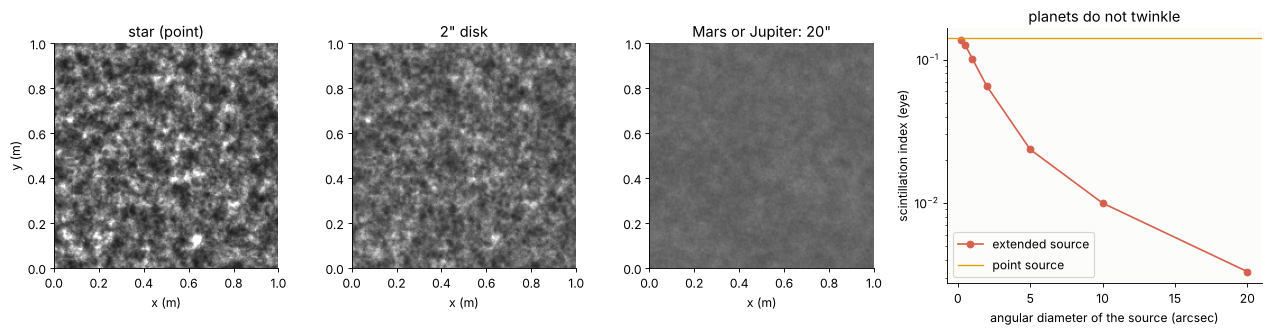

In [8]:
rng = np.random.default_rng(5)
uv = rng.uniform(-1, 1, (400, 2))
uv = uv[np.hypot(uv[:, 0], uv[:, 1]) <= 1][:120]          # points on the planet's disk
diameters = np.array([0, 0.25, 0.5, 1, 2, 5, 10, 20])     # arcsec
w_p = 256
idx_p = np.arange(-w_p, w_p)
s2_planet, maps = [], {}
for d_as in diameters:
    I_sum = 0.0
    pts = uv if d_as > 0 else np.zeros((1, 2))
    for ux, uy in pts:
        theta = np.array([ux, uy])*d_as/2*ARCSEC
        chi = 0.0
        for i in range(len(H)):
            sx, sy = np.round(theta*H[i]/dx_t).astype(int)
            chi = chi + chi_layers[i][np.ix_((N_t//2 + idx_p + sy) % N_t, (N_t//2 + idx_p + sx) % N_t)]
        I_sum = I_sum + np.exp(2*chi)
    I_sum /= I_sum.mean()
    s2_planet.append(I_sum.var())
    maps[d_as] = I_sum

fig, ax = plt.subplots(1, 4, figsize=(16, 4.3), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.4]))
for a, d_as, name in zip(ax[:3], [0, 2, 20], ["star (point)", "2\" disk", "Mars or Jupiter: 20\""]):
    a.imshow(maps[d_as][:200, :200], extent=[0, 1, 0, 1], cmap="gray", vmin=0, vmax=2.5)
    a.set_title(name)
    a.set_xlabel("x (m)")
ax[0].set_ylabel("y (m)")
ax[3].semilogy(diameters[1:], s2_planet[1:], "o-", color="#d6604d", label="extended source")
ax[3].axhline(s2_planet[0], color="#e0a000", lw=1.2, label="point source")
ax[3].set_xlabel("angular diameter of the source (arcsec)")
ax[3].set_ylabel("scintillation index (eye)")
ax[3].set_title("planets do not twinkle")
ax[3].legend()
plt.tight_layout()

Already a disk of two arcseconds halves the scintillation index seen by
the eye; at the 10 to 20 arcseconds of Mars, Saturn or Jupiter it is
down by a factor of 15 to 40, and the flux varies by only a few per cent. (Real
scintillation also has colours: the Fresnel scale and the refraction of
the atmosphere depend on the wavelength, so near the horizon a star
flickers in red and blue.)

## 4. The speckled star: short and long exposures

A large telescope does not see the twinkling, but it sees the phase. Over
its aperture of $D = 4$ m there are $(D/r_0)^2 \approx 1500$ patches of
size $r_0$ with independent phases. A **short exposure** (shorter than
$\tau_0$, a few ms) shows the interference of these patches: a cloud of
speckles of size $\lambda/D$, spread over $\lambda/r_0$. A **long
exposure** averages the moving speckle pattern into the smooth seeing
disk of FWHM $0.976\,\lambda/r_0$.

Fried (1966) gave the transfer functions. Long exposures multiply the
telescope OTF by the atmospheric transfer function
$\exp[-3.44\,(\lambda\nu/r_0)^{5/3}]$ ($\nu$ in cycles per radian);
recentring each short exposure on its centroid (removing the tilt)
raises it to $\exp\{-3.44\,(\lambda\nu/r_0)^{5/3}[1 - (\lambda\nu/D)^{1/3}]\}$.
The speckles themselves carry information up to the diffraction limit:
the average power spectrum of short exposures falls only to about
$0.435\,(r_0/D)^2$ of its zero frequency value (Labeyrie's speckle
interferometry). Below: 100 independent short exposures at 500 nm with
the $r_0$ of our atmosphere.

seeing FWHM: simulated 1.05", theory 0.99"
r0 from the long exposure OTF: 11.3 cm (atmosphere: 10.2 cm)
peak of a short exposure: 0.0068 of the diffraction peak, of the long exposure 0.00081; (r0/D)^2 = 0.00065


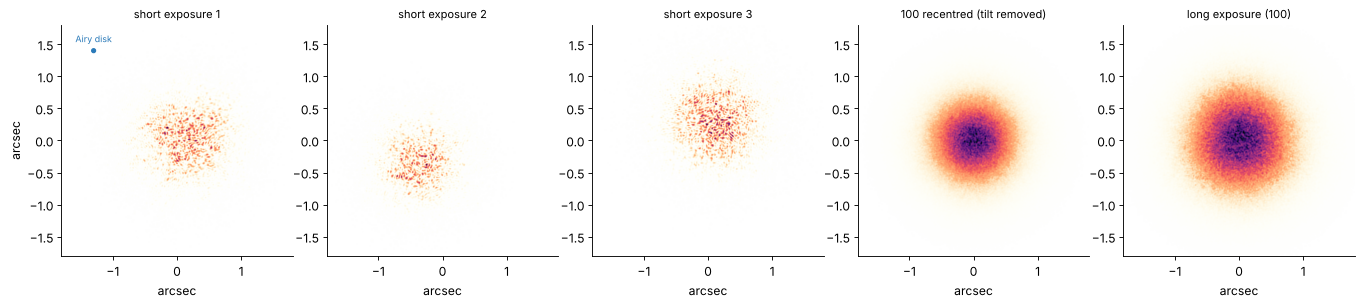

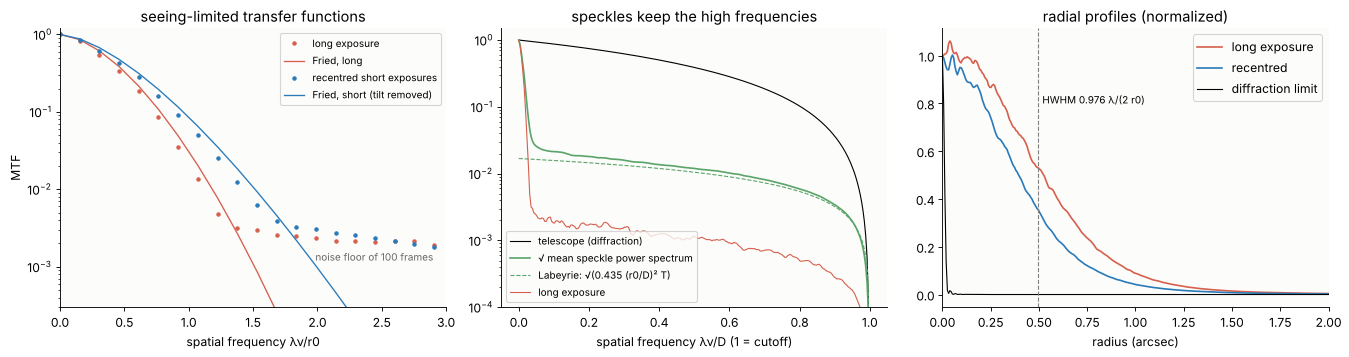

In [9]:
D_tel, n_p = 4.0, 256
dx_p = D_tel/n_p
xp = (np.arange(n_p) - n_p/2 + 0.5)*dx_p
XP, YP = np.meshgrid(xp, xp)
pupil = XP**2 + YP**2 <= (D_tel/2)**2
pad = 1024
pix = WL0/(pad*dx_p)                              # PSF pixel in rad (lambda/(4D))
psf_dl = psf(pupil.astype(complex), pad)
peak_dl = psf_dl.max()
c0 = pad//2
I_long, I_tilt, P_spec, shorts = 0.0, 0.0, 0.0, []
for i in range(100):
    phi = turbulence.phase_screen(512, dx_p, R0, rng=2000 + i)[128:384, 128:384]
    p_short = psf(pupil*np.exp(1j*phi), pad)/peak_dl
    if i < 3:
        shorts.append(p_short)
    I_long = I_long + p_short
    iy, ix = np.indices(p_short.shape)
    cy, cx = (np.sum(iy*p_short)/p_short.sum(), np.sum(ix*p_short)/p_short.sum())
    I_tilt = I_tilt + np.roll(p_short, (int(round(c0 - cy)), int(round(c0 - cx))), axis=(0, 1))
    P_spec = P_spec + np.abs(fft2(p_short))**2
I_long /= 100
I_tilt /= 100

ext = [-c0*pix/ARCSEC, (pad - c0)*pix/ARCSEC]*2
zoom = slice(c0 - 280, c0 + 280)
ext_z = [-280*pix/ARCSEC, 280*pix/ARCSEC]*2
fig, ax = plt.subplots(1, 5, figsize=(17, 3.9))
for a, img, name in zip(ax, shorts + [I_tilt, I_long],
                        ["short exposure 1", "short exposure 2", "short exposure 3",
                         "100 recentred (tilt removed)", "long exposure (100)"]):
    a.imshow(img[zoom, zoom], extent=ext_z, cmap=LIGHT, vmin=0, vmax=img[zoom, zoom].max())
    a.set_title(name, fontsize=10)
    a.set_xlabel("arcsec")
ax[0].set_ylabel("arcsec")
ax[0].add_patch(plt.Circle((-1.3, 1.4), 1.22*WL0/D_tel/ARCSEC, color="#2a7ab9"))
ax[0].text(-1.3, 1.5, "Airy disk", color="#2a7ab9", ha="center", va="bottom", fontsize=8)
plt.tight_layout()

# transfer functions
dnu = 1/(pad*pix)                                         # cycles/rad per OTF pixel
otf_dl = radial_mean(np.abs(np.fft.fftshift(fft2(psf_dl))))
otf_long = radial_mean(np.abs(np.fft.fftshift(fft2(I_long))))
otf_tilt = radial_mean(np.abs(np.fft.fftshift(fft2(I_tilt))))
spec = radial_mean(np.fft.fftshift(P_spec))
nu_r = np.arange(len(otf_dl))*dnu
cut = WL0*nu_r <= D_tel
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
x_r = WL0*nu_r[cut]/R0
T_dl = otf_dl[cut]/otf_dl[0]
ax[0].semilogy(x_r, otf_long[cut]/otf_long[0], "o", ms=3, color="#d6604d", label="long exposure")
ax[0].semilogy(x_r, T_dl*turbulence.atmospheric_otf(nu_r[cut], R0, WL0), "-", color="#d6604d",
               lw=1.2, label="Fried, long")
ax[0].semilogy(x_r, otf_tilt[cut]/otf_tilt[0], "o", ms=3, color="#2a7ab9",
               label="recentred short exposures")
ax[0].semilogy(x_r, T_dl*turbulence.atmospheric_otf(nu_r[cut], R0, WL0, D=D_tel), "-",
               color="#2a7ab9", lw=1.2, label="Fried, short (tilt removed)")
ax[0].set_xlim(0, 3)
ax[0].set_ylim(3e-4, 1.2)
ax[0].set_xlabel("spatial frequency λν/r0")
ax[0].set_ylabel("MTF")
ax[0].set_title("seeing-limited transfer functions")
ax[0].legend(fontsize=9)
ax[0].text(2.9, 1.2e-3, "noise floor of 100 frames", ha="right", fontsize=9, color="0.4")
x_n = WL0*nu_r[cut]/D_tel
ax[1].semilogy(x_n, T_dl, "k-", lw=1, label="telescope (diffraction)")
ax[1].semilogy(x_n, np.sqrt(spec[cut]/spec[0]), "-", color="#5aa469", lw=1.5,
               label="√ mean speckle power spectrum")
ax[1].semilogy(x_n, np.sqrt(0.435*(R0/D_tel)**2*T_dl), "--", color="#5aa469", lw=1,
               label="Labeyrie: √(0.435 (r0/D)² T)")
ax[1].semilogy(x_n, otf_long[cut]/otf_long[0], "-", color="#d6604d", lw=1, label="long exposure")
ax[1].set_ylim(1e-4, 1.5)
ax[1].set_xlabel("spatial frequency λν/D (1 = cutoff)")
ax[1].set_title("speckles keep the high frequencies")
ax[1].legend(fontsize=9)
# r0 from the long exposure: ln(OTF_long/OTF_tel) = -3.44 (lambda nu/r0)^(5/3)
fit = cut & (WL0*nu_r > 0.02) & (WL0*nu_r < 0.25)
ratio = -np.log(otf_long[fit]/otf_long[0]/(otf_dl[fit]/otf_dl[0]))
r0_otf = np.exp(np.mean(np.log(WL0*nu_r[fit]) - 0.6*np.log(ratio/3.44)))
prof_long = radial_mean(I_long)
r_as = np.arange(len(prof_long))*pix/ARCSEC
half = np.interp(0.5, prof_long[::-1]/prof_long[0], r_as[::-1])
ax[2].plot(r_as, prof_long/prof_long[0], color="#d6604d", label="long exposure")
ax[2].plot(r_as, radial_mean(I_tilt)/radial_mean(I_tilt)[0], color="#2a7ab9", label="recentred")
ax[2].plot(r_as, radial_mean(psf_dl/peak_dl), "k-", lw=1, label="diffraction limit")
ax[2].axvline(turbulence.seeing_fwhm(R0, WL0)/2/ARCSEC, color="0.5", ls="--", lw=1)
ax[2].text(turbulence.seeing_fwhm(R0, WL0)/2/ARCSEC*1.05, 0.8, "HWHM 0.976 λ/(2 r0)", fontsize=9)
ax[2].set_xlim(0, 2)
ax[2].set_xlabel("radius (arcsec)")
ax[2].set_title("radial profiles (normalized)")
ax[2].legend()
plt.tight_layout()
print("seeing FWHM: simulated {:.2f}\", theory {:.2f}\"".format(
    2*half, turbulence.seeing_fwhm(R0, WL0)/ARCSEC))
print("r0 from the long exposure OTF: {:.1f} cm (atmosphere: {:.1f} cm)".format(
    100*r0_otf, 100*R0))
print("peak of a short exposure: {:.4f} of the diffraction peak, of the long exposure {:.5f}; "
      "(r0/D)^2 = {:.5f}".format(np.mean([s.max() for s in shorts]), I_long.max(), (R0/D_tel)**2))

The long and the recentred exposures follow Fried's transfer functions
down to the noise floor of 100 frames, and the seeing disk and $r_0$
recovered from the images agree with the layer model to within 5 to 10 %
(100 frames hold few independent realizations of the largest scales). Removing the tilt sharpens the core only a little at
$D/r_0 = 40$: most of the blur comes from the higher modes. The square
root of the averaged speckle power spectrum, on the other hand, stays
far above the long exposure MTF all the way to the cutoff, close to
Labeyrie's estimate: the speckles
hold diffraction-limited information, which is what speckle
interferometry and, in a different way, adaptive optics exploit.

## 5. Lucky imaging

For $D$ of a few $r_0$ the number of independent patches is small, and
now and then the atmosphere happens to be almost flat over the whole
aperture. Fried (1978) estimated the probability that the phase variance,
with piston and tilt removed, is below 1 rad²:
$P \approx 5.6\,\exp[-0.1557\,(D/r_0)^2]$ for $D/r_0 \gtrsim 3.5$. It falls
so fast that lucky imaging is limited to $D/r_0$ below about 7, i.e. to
2 m telescopes in the red or near infrared. The phase scales as
$r_0^{-5/6}$, so one set of screens serves for all $D/r_0$.

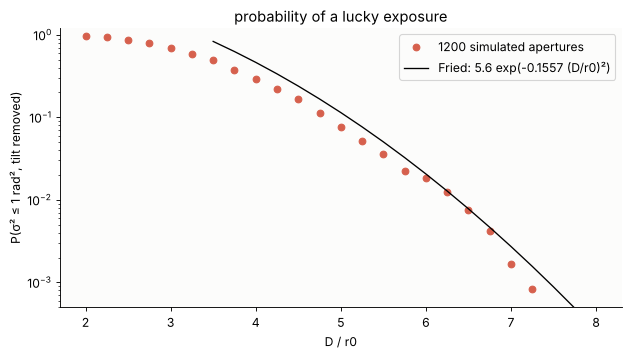

In [10]:
n_l = 96
xl = (np.arange(n_l) - n_l/2 + 0.5)/(n_l/2)
XL, YL = np.meshgrid(xl, xl)
pup_l = XL**2 + YL**2 <= 1
A_tilt = np.c_[np.ones(pup_l.sum()), XL[pup_l], YL[pup_l]]
lucky_phases, var_unit = [], []
for i in range(300):                       # D/r0 = 1 for these screens; 4 pupils per screen
    s = turbulence.phase_screen(2*n_l, 1/n_l, 1.0, rng=5000 + i)
    for qy in (0, n_l):
        for qx in (0, n_l):
            phi = s[qy:qy + n_l, qx:qx + n_l]
            res = phi[pup_l] - A_tilt@np.linalg.lstsq(A_tilt, phi[pup_l], rcond=None)[0]
            lucky_phases.append(phi)
            var_unit.append(res.var())
var_unit = np.array(var_unit)
DR = np.linspace(2, 8, 25)
P_sim = [np.mean(var_unit*dr**(5/3) <= 1) for dr in DR]

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.semilogy(DR, P_sim, "o", color="#d6604d", label="{} simulated apertures".format(len(var_unit)))
ax.semilogy(DR[DR >= 3.5], turbulence.lucky_probability(DR[DR >= 3.5]), "k-", lw=1.2,
            label="Fried: 5.6 exp(-0.1557 (D/r0)²)")
ax.set_ylim(5e-4, 1.2)
ax.set_xlabel("D / r0")
ax.set_ylabel("P(σ² ≤ 1 rad², tilt removed)")
ax.set_title("probability of a lucky exposure")
ax.legend()
plt.tight_layout()

Now a lucky imaging run: 1200 short exposures at $D/r_0 = 5$ of a close
binary star, two stars $2\lambda/D$ apart with a flux ratio of 0.4. The
frames are ranked by their brightest pixel (the usual proxy for the
Strehl ratio), and the best 1 %, 10 % and all frames are shifted onto
their brightest pixel and added ("shift and add").

Strehl proxy of the frames: median 0.22, best 1 % from 0.50


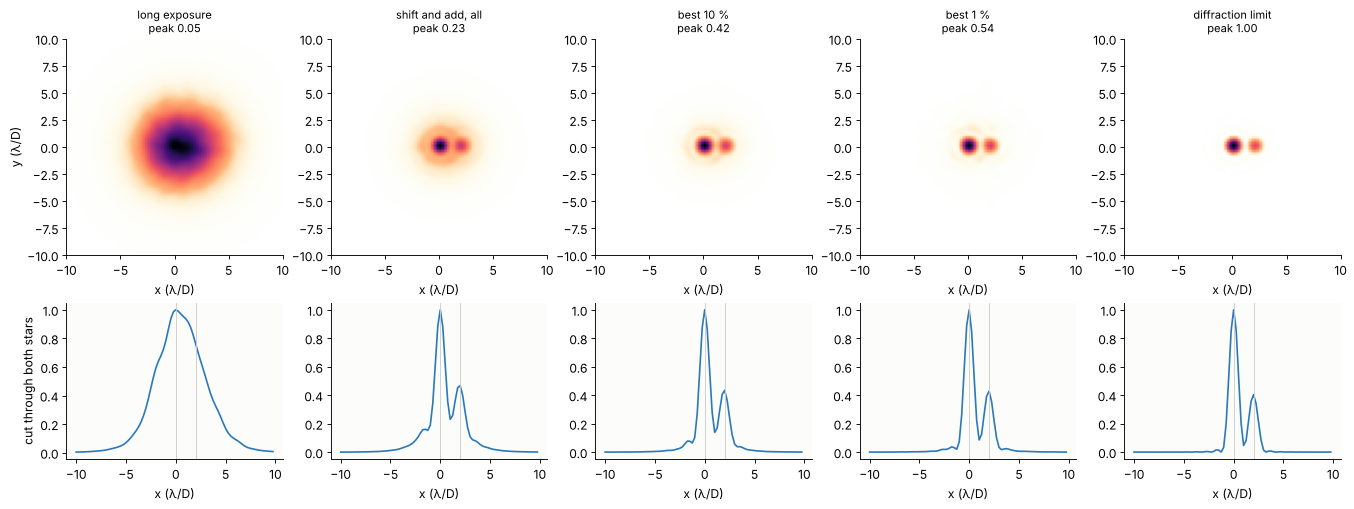

In [11]:
dr_l = 5.0
pad_l = 4*n_l
sep = 8                                    # 2 lambda/D in pixels of lambda/(4D)
P_amp = pup_l.astype(float)
peak_dl_l = psf(P_amp.astype(complex), pad_l).max()
c_l = pad_l//2


def frame(k):
    """Short exposure k of the binary star (peak of a single star = Strehl)."""
    p = psf(P_amp*np.exp(1j*lucky_phases[k]*dr_l**(5/6)), pad_l)/peak_dl_l
    return p + 0.4*np.roll(p, sep, axis=1)


def shift_and_add(sel):
    out = 0.0
    for k in sel:
        img = frame(k)
        iy, ix = np.unravel_index(np.argmax(img), img.shape)
        out = out + np.roll(img, (c_l - iy, c_l - ix), axis=(0, 1))
    return out/len(sel)


peaks, long_l = [], 0.0
for k in range(len(lucky_phases)):
    img = frame(k)
    peaks.append(img.max())
    long_l = long_l + img
peaks = np.array(peaks)
rank = np.argsort(peaks)[::-1]
ideal = psf(P_amp.astype(complex), pad_l)/peak_dl_l
ideal = ideal + 0.4*np.roll(ideal, sep, axis=1)
results = [("long exposure", long_l/len(peaks)),
           ("shift and add, all", shift_and_add(rank)),
           ("best 10 %", shift_and_add(rank[:len(rank)//10])),
           ("best 1 %", shift_and_add(rank[:len(rank)//100])),
           ("diffraction limit", ideal)]
zl = slice(c_l - 40, c_l + 40)
ext_l = [-10, 10, -10, 10]                 # in lambda/D
fig, ax = plt.subplots(2, 5, figsize=(17, 6.4), gridspec_kw=dict(height_ratios=[1.5, 1]))
for i, (name, img) in enumerate(results):
    ax[0, i].imshow(img[zl, zl], extent=ext_l, cmap=LIGHT, vmin=0, vmax=img[zl, zl].max())
    ax[0, i].set_title("{}\npeak {:.2f}".format(name, img.max()), fontsize=10)
    ax[0, i].set_xlabel("x (λ/D)")
    row = img[c_l, c_l - 40:c_l + 40]
    ax[1, i].plot(np.arange(-40, 40)/4, row/row.max(), color="#2a7ab9")
    ax[1, i].axvline(0, color="0.8", lw=0.8); ax[1, i].axvline(sep/4, color="0.8", lw=0.8)
    ax[1, i].set_xlabel("x (λ/D)")
ax[0, 0].set_ylabel("y (λ/D)")
ax[1, 0].set_ylabel("cut through both stars")
plt.tight_layout()
print("Strehl proxy of the frames: median {:.2f}, best 1 % from {:.2f}".format(
    np.median(peaks)/1.0, peaks[rank[len(rank)//100]]))

Fried's estimate has the right steep fall-off, but it is a rough fit:
for $D/r_0$ = 4 to 5 the simulated apertures are lucky only about half
as often as the formula says; from about 6 on the two agree.

The long exposure is a single blob. Shift and add of all frames already
shows the companion, on a halo and with a peak of only 0.23; the best
10 % and 1 % of the frames raise the peak to 0.4 to 0.5 and nearly
reach the diffraction-limited image, at the cost of 90 to 99 % of the
light. Adaptive optics keeps all the light.

## 6. Adaptive optics

An adaptive optics (AO) system measures the wavefront a thousand times
per second and flattens it with a deformable mirror (DM), see the sketch
at the top. Our model of a 4 m telescope:

- **atmosphere**: the eight layers of section 2 as large screens (16 m,
  with subharmonics) that move with their winds (`turbulence.FrozenFlow`).
  All layers are summed in the pupil as optical path differences (OPD),
  which are the same at all wavelengths; scintillation is neglected (it
  is weak at the telescope, section 3), and the star is on axis.
- **wavefront sensor**: a Shack-Hartmann sensor with 16 × 16 lenslets of
  25 cm in the pupil, working at 700 nm, with 16 × 16 camera pixels per
  lenslet (`shack_hartmann.ShackHartmann`, the real spot images and
  centroids, without noise).
- **deformable mirror**: either a **zonal** DM with 17 × 17 actuators at
  the corners of the lenslets (Fried geometry), Gaussian influence
  functions with 15 % coupling to the neighbours, of which the 249 that
  touch the pupil are used; or a **modal** DM that makes the Fringe
  Zernikes up to the radial order 14 (119 modes, piston left out).
- **control**: the interaction matrix is measured by pushing every
  actuator (mode) up and down and recording the slopes; its pseudo-inverse
  (truncated SVD) is the reconstructor. An integrator with gain 0.5 adds
  the reconstructed correction, one frame (1 ms) after the measurement.
- **science camera**: in the H band (1.65 µm); the Strehl ratio is
  $|\langle e^{i 2\pi W/\lambda}\rangle_{\rm pupil}|^2$ for the residual
  OPD $W$, the definition of `imaging.strehl_ratio()` in notebook 17.

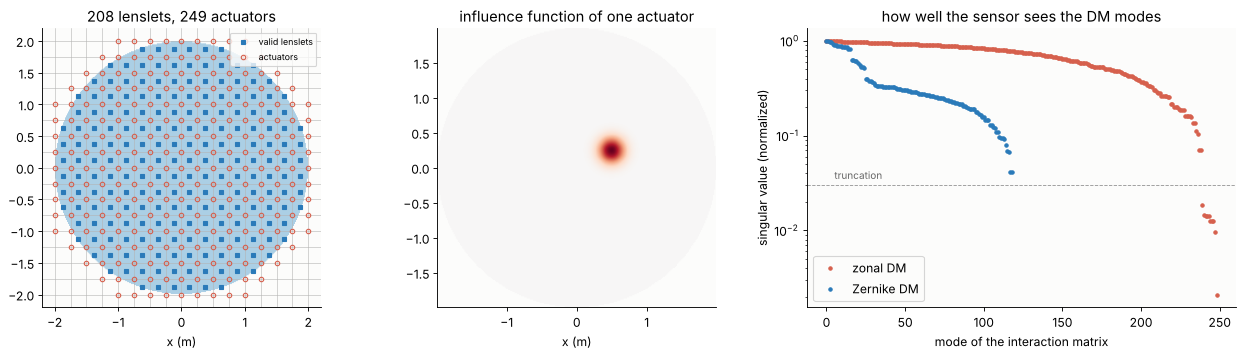

In [12]:
n_sh, pitch, WFS = 16, D_tel/16, 0.7e-6
sh = ShackHartmann(n_sh, pitch, pitch**2/(8*WFS), WFS, pixels=16, samples=16)
N_ao = sh.P_x.shape[0]                     # 256 samples over 4 m
dx_ao = sh.dx
pup_ao = sh.P_x**2 + sh.P_y**2 <= 1
T_AO, DT = 0.3, 1e-3
vel = np.c_[SPEEDS*np.cos(ANGLES), SPEEDS*np.sin(ANGLES)]
opd_screens = [turbulence.phase_screen(1024, dx_ao, turbulence.fried_parameter(c, WL0),
                                       rng=300 + i)*WL0/(2*np.pi) for i, c in enumerate(CN2)]
flow = turbulence.FrozenFlow(opd_screens, dx_ao, vel, (N_ao, N_ao), t_mid=T_AO/2)

ref_img = sh.spots(sh.field(None))
valid = sh.slopes(ref_img, ref_img, min_flux=0.2).valid


def measure(W):
    """Shack-Hartmann slopes of the residual OPD W (valid lenslets, x then y)."""
    s = sh.slopes(sh.spots(sh.field(2*np.pi*W/WFS)), ref_img, threshold=0.0, min_flux=0.0)
    return np.concatenate([s.sx[valid], s.sy[valid]])


# zonal DM: actuators on the lenslet corners
ac = (np.arange(n_sh + 1) - n_sh/2)*pitch
AX, AY = np.meshgrid(ac, ac)
act = np.hypot(AX, AY) <= D_tel/2 + pitch
XA, YA = np.meshgrid(sh.x, sh.y)
infl = np.array([np.exp(np.log(0.15)*((XA - ax_)**2 + (YA - ay_)**2)/pitch**2)
                 for ax_, ay_ in zip(AX[act], AY[act])])
# modal DM: Fringe Zernikes up to n = 14, RMS 1 m over the pupil
js_ao = [j for j in range(2, 300) if fringe_to_n_m(j)[0] <= 14]
zern = np.array([np.where(pup_ao, fringe_zernike(j, sh.P_x, sh.P_y)/np.sqrt(fringe_zernike_norm(j)/np.pi), 0.0)
                 for j in js_ao])


def interaction_matrix(modes, amp=20e-9):
    return np.array([(measure(amp*m) - measure(-amp*m))/(2*amp) for m in modes]).T


def reconstructor(IM, cut):
    U, S, Vt = np.linalg.svd(IM, full_matrices=False)
    keep = S > cut*S[0]
    return (Vt[keep].T/S[keep])@U[:, keep].T, S


IM_zonal = interaction_matrix(infl)
IM_modal = interaction_matrix(zern)
R_zonal, S_zonal = reconstructor(IM_zonal, 0.03)
R_modal, S_modal = reconstructor(IM_modal, 0.0)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
ax[0].imshow(np.where(pup_ao, 1.0, np.nan), extent=[sh.x[0], sh.x[-1]]*2, cmap="Blues", vmin=0, vmax=3)
for c in np.r_[sh.centers - pitch/2, sh.centers[-1] + pitch/2]:
    ax[0].axvline(c, color="0.7", lw=0.5); ax[0].axhline(c, color="0.7", lw=0.5)
vy, vx = np.nonzero(valid)
ax[0].plot(sh.centers[vx], sh.centers[vy], "s", ms=3, color="#2a7ab9", label="valid lenslets")
ax[0].plot(AX[act], AY[act], "o", ms=4, mfc="none", color="#d6604d", label="actuators")
ax[0].set_title("{} lenslets, {} actuators".format(valid.sum(), act.sum()))
ax[0].set_xlabel("x (m)")
ax[0].legend(loc="upper right", fontsize=8)
k_show = np.argmin(np.hypot(AX[act] - 0.5, AY[act] - 0.25))
im = ax[1].imshow(np.where(pup_ao, infl[k_show], np.nan), extent=[sh.x[0], sh.x[-1]]*2, cmap="RdBu_r",
                  vmin=-1, vmax=1)
ax[1].set_title("influence function of one actuator")
ax[1].set_xlabel("x (m)")
ax[2].semilogy(S_zonal/S_zonal[0], ".", color="#d6604d", label="zonal DM")
ax[2].semilogy(S_modal/S_modal[0], ".", color="#2a7ab9", label="Zernike DM")
ax[2].axhline(0.03, color="0.6", ls="--", lw=0.8)
ax[2].text(5, 0.035, "truncation", fontsize=9, color="0.4")
ax[2].set_xlabel("mode of the interaction matrix")
ax[2].set_ylabel("singular value (normalized)")
ax[2].set_title("how well the sensor sees the DM modes")
ax[2].legend()
plt.tight_layout()

The singular values of the zonal interaction matrix fall smoothly until
the last one, two orders of magnitude lower: the **waffle mode**, a
checkerboard of the actuators that a Shack-Hartmann sensor in Fried
geometry cannot see. The truncation drops it. All Zernike modes are
visible to the sensor.

Now the loops. The first runs open (no correction), then the zonal DM at
1 kHz, the Zernike DM at 1 kHz, and the zonal DM at 200 Hz (measurement
and update every 5 ms), all through the same 0.3 s of atmosphere.

four loops of 300 frames: 62 s
mean over the last 250 ms         RMS (nm)     S_J     S_H     S_K
open loop                             1863   0.005   0.012   0.019
zonal DM, 1 kHz                        104   0.761   0.855   0.915
Zernike DM (119 modes), 1 kHz          153   0.647   0.774   0.862
zonal DM, 200 Hz                       174   0.468   0.645   0.780


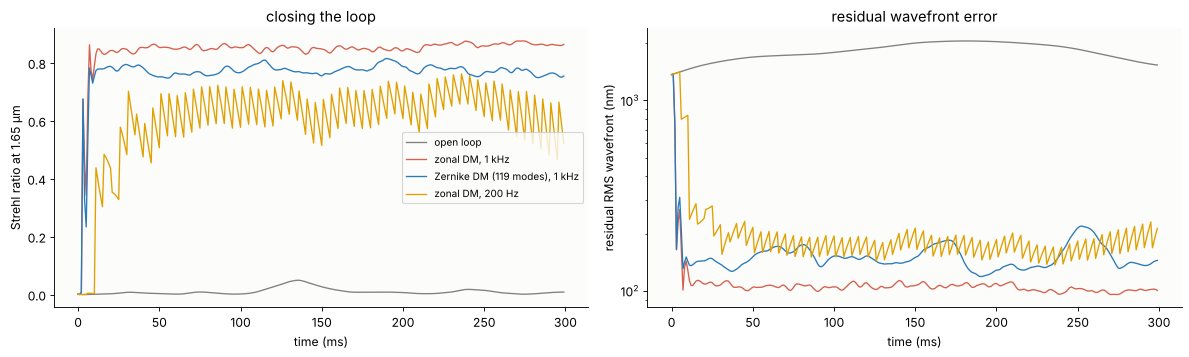

In [13]:
LAMBDAS = {"J": 1.25e-6, "H": 1.65e-6, "K": 2.2e-6}
pad_ao = 512
pix_ao = LAMBDAS["H"]/(pad_ao*dx_ao)
psf_dl_ao = psf(pup_ao.astype(complex), pad_ao)
peak_ao = psf_dl_ao.max()


def strehl(W, wl):
    return np.abs(np.mean(np.exp(2j*np.pi*W[pup_ao]/wl)))**2


def run_loop(modes, R, gain=0.5, every=1, n_frames=int(T_AO/DT), keep_psf=False):
    cmd = np.zeros(len(modes)) if modes is not None else None
    pending, out = None, dict(S={b: [] for b in LAMBDAS}, rms=[], psf=0.0, short=None, W=None)
    for k in range(n_frames):
        W = flow(k*DT)
        if modes is not None:
            W = W - np.tensordot(cmd, modes, 1)
        Wp = W[pup_ao] - W[pup_ao].mean()
        out["rms"].append(Wp.std())
        for b, wl in LAMBDAS.items():
            out["S"][b].append(strehl(W, wl))
        if keep_psf and k >= 50:
            p = psf(np.where(pup_ao, np.exp(2j*np.pi*W/LAMBDAS["H"]), 0), pad_ao)/peak_ao
            out["psf"] = out["psf"] + p
            if k == n_frames - 1:
                out["short"], out["W"] = p, np.where(pup_ao, W - W[pup_ao].mean(), np.nan)
        if modes is None:
            continue
        if pending is not None and k % every == 0:      # apply the last measurement (delay)
            cmd = cmd + pending
            pending = None
        if k % every == 0:
            pending = gain*(R@measure(W))
    out["psf"] = out["psf"]/(n_frames - 50) if keep_psf else None
    out["rms"] = np.array(out["rms"])
    out["S"] = {b: np.array(v) for b, v in out["S"].items()}
    return out


t0 = time.time()
loops = {"open loop": run_loop(None, None, keep_psf=True),
         "zonal DM, 1 kHz": run_loop(infl, R_zonal, keep_psf=True),
         "Zernike DM (119 modes), 1 kHz": run_loop(zern, R_modal),
         "zonal DM, 200 Hz": run_loop(infl, R_zonal, every=5)}
print("four loops of {:.0f} frames: {:.0f} s".format(T_AO/DT, time.time() - t0))
colors = {"open loop": "0.5", "zonal DM, 1 kHz": "#d6604d",
          "Zernike DM (119 modes), 1 kHz": "#2a7ab9", "zonal DM, 200 Hz": "#e0a000"}
t_ao = np.arange(int(T_AO/DT))*DT

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for name, o in loops.items():
    ax[0].plot(1e3*t_ao, o["S"]["H"], color=colors[name], lw=1.2, label=name)
    ax[1].semilogy(1e3*t_ao, 1e9*o["rms"], color=colors[name], lw=1.2, label=name)
ax[0].set_xlabel("time (ms)")
ax[0].set_ylabel("Strehl ratio at 1.65 µm")
ax[0].set_title("closing the loop")
ax[0].legend(fontsize=9, loc="center right")
ax[1].set_xlabel("time (ms)")
ax[1].set_ylabel("residual RMS wavefront (nm)")
ax[1].set_title("residual wavefront error")
plt.tight_layout()
print("{:32s} {:>9s} {:>7s} {:>7s} {:>7s}".format("mean over the last 250 ms", "RMS (nm)", "S_J",
                                                  "S_H", "S_K"))
for name, o in loops.items():
    print("{:32s} {:9.0f} {:7.3f} {:7.3f} {:7.3f}".format(
        name, 1e9*o["rms"][50:].mean(), *[o["S"][b][50:].mean() for b in LAMBDAS]))

Within a few milliseconds the loop pulls the Strehl ratio from about 1 %
to 0.85 and holds it there; the residual wavefront drops from almost two
micrometres to about 100 nm. The Zernike DM ends up somewhat worse: its 119
modes leave more of the high spatial frequencies than 249 actuators. At
200 Hz the loop lags behind the wind and the Strehl ratio fluctuates
around a lower level. What a long exposure looks like with and without
AO:

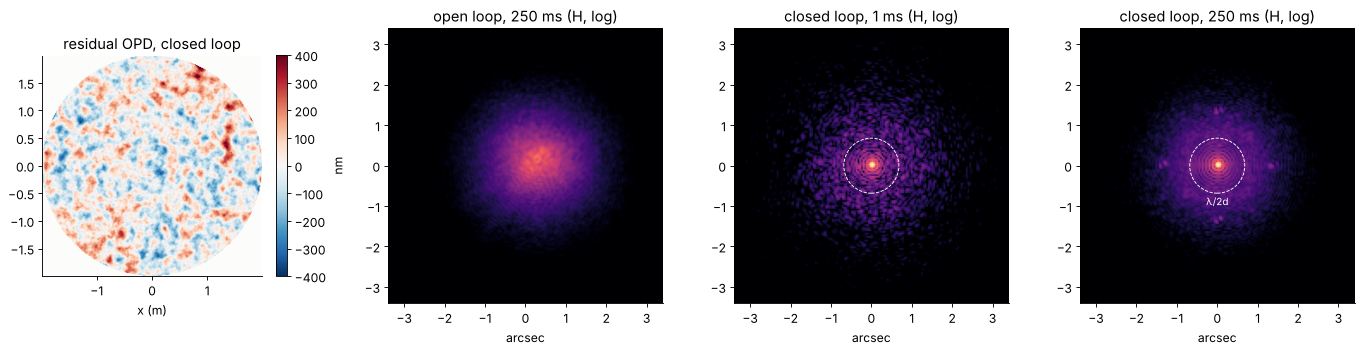

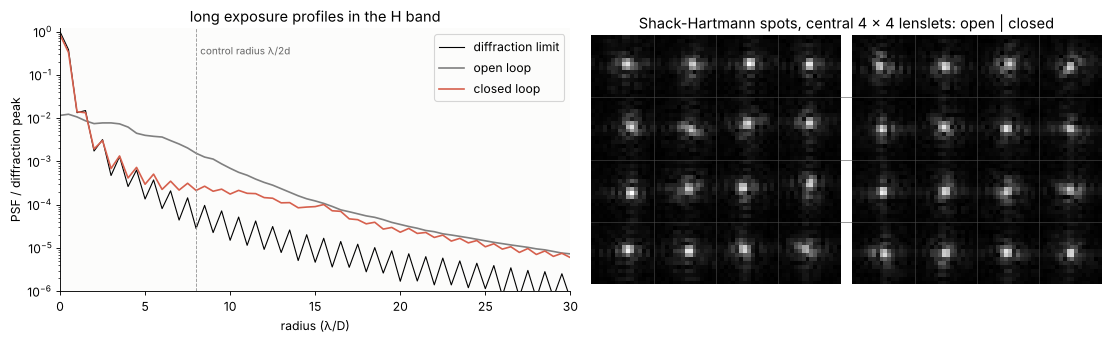

In [14]:
o_open, o_cl = loops["open loop"], loops["zonal DM, 1 kHz"]
c_ao = pad_ao//2
zo = slice(c_ao - 80, c_ao + 80)
ext_ao = [-80*pix_ao/ARCSEC, 80*pix_ao/ARCSEC]*2
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
im = ax[0].imshow(o_cl["W"]*1e9, extent=[sh.x[0], sh.x[-1]]*2, cmap="RdBu_r", vmin=-400, vmax=400)
ax[0].set_title("residual OPD, closed loop")
ax[0].set_xlabel("x (m)")
plt.colorbar(im, ax=ax[0], shrink=0.8, label="nm")
for a, img, name in zip(ax[1:], [o_open["psf"], o_cl["short"], o_cl["psf"]],
                        ["open loop, 250 ms", "closed loop, 1 ms", "closed loop, 250 ms"]):
    a.imshow(img[zo, zo], extent=ext_ao, cmap="magma", norm=LogNorm(vmin=1e-5, vmax=1))
    a.set_title(name + " (H, log)")
    a.set_xlabel("arcsec")
r_ctrl = LAMBDAS["H"]/(2*pitch)/ARCSEC
for a in ax[2:]:
    a.add_patch(plt.Circle((0, 0), r_ctrl, fill=False, ls="--", color="w", lw=0.8))
ax[3].text(0, -r_ctrl*1.08, "λ/2d", color="w", ha="center", va="top", fontsize=9)
plt.tight_layout()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
r_ao = np.arange(c_ao)*pix_ao/(LAMBDAS["H"]/D_tel)
ax[0].semilogy(r_ao, radial_mean(psf_dl_ao/peak_ao), "k-", lw=1, label="diffraction limit")
ax[0].semilogy(r_ao, radial_mean(o_open["psf"]), color="0.5", label="open loop")
ax[0].semilogy(r_ao, radial_mean(o_cl["psf"]), color="#d6604d", label="closed loop")
ax[0].axvline(D_tel/(2*pitch), color="0.6", ls="--", lw=0.8)
ax[0].text(D_tel/(2*pitch)*1.03, 0.3, "control radius λ/2d", fontsize=9, color="0.4")
ax[0].set_xlim(0, 30)
ax[0].set_ylim(1e-6, 1.2)
ax[0].set_xlabel("radius (λ/D)")
ax[0].set_ylabel("PSF / diffraction peak")
ax[0].set_title("long exposure profiles in the H band")
ax[0].legend()
# Shack-Hartmann images open and closed
W_open = flow(0.0)
img_open = sh.spots(sh.field(2*np.pi*W_open/WFS))
img_cl = sh.spots(sh.field(2*np.pi*np.nan_to_num(o_cl["W"])/WFS))
q = slice(16*6, 16*10)                   # the central 4 x 4 lenslets
ax[1].imshow(np.hstack([img_open[q, q], np.full((64, 3), np.nan), img_cl[q, q]])**0.5,
             cmap="gray")
for c in range(1, 4):
    for off in (0, 67):
        ax[1].axvline(off + 16*c - 0.5, color="0.3", lw=0.5)
    ax[1].axhline(16*c - 0.5, color="0.3", lw=0.5)
ax[1].set_title("Shack-Hartmann spots, central 4 × 4 lenslets: open | closed")
ax[1].axis("off")
plt.tight_layout()

The corrected PSF has a diffraction-limited core on a halo. Inside the
**control radius** $\lambda/2d$ (8 $\lambda/D$ for the pitch $d$ of 25 cm)
the DM removes the turbulence and the halo drops by more than an order
of magnitude; outside it the DM cannot make the spatial frequencies and
the halo follows the seeing. The four faint spots at $\lambda/d$ are the
grating of the actuators printed through the DM surface. The spots of the sensor, scattered in open loop,
sit on their reference positions in closed loop.

### The error budget

The residual variance is the sum of independent terms:

- **fitting error**: the DM cannot make the fine structure;
  $a_F\,(d/r_0)^{5/3}$ with $a_F \approx 0.28$ for a continuous facesheet
  DM, or Noll's $\Delta_J (D/r_0)^{5/3}$ for a Zernike DM with $J$ modes,
- **servo lag**: the correction comes a delay $\tau$ too late; a perfect
  correction delayed by $\tau$ leaves $(\tau/\tau_0)^{5/3}$,
- **aliasing**: the sensor mistakes the fine structure for coarse slopes
  and the loop puts it on the DM.

(Photon and read noise, which set the limit for faint guide stars, are
left out here; see `processing.CameraNoiser` in notebook 18.) The
fitting error is measured by projecting the instantaneous atmosphere on
the DM modes, the aliasing by feeding only the part the DM cannot make
to the sensor and the reconstructor.

term                                 simulated (nm)  theory (nm)
fitting, zonal DM                                82           89
fitting, Zernike DM                             113          116
aliasing, zonal DM                               50          nan
servo lag, 1 kHz (τ = 1.5 ms)                   nan           46
servo lag, 200 Hz (τ = 7.5 ms)                  nan          176
zonal, 1 kHz: sum of the terms 107 nm, loop 104 nm


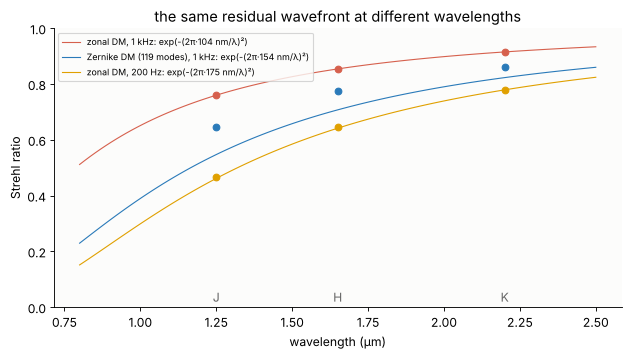

In [15]:
fit_z, fit_m, alias = [], [], []
A_z, A_m = infl[:, pup_ao].T, zern[:, pup_ao].T
for k in range(0, 300, 30):
    W = flow(k*DT)
    w = W[pup_ao] - W[pup_ao].mean()
    cz = np.linalg.lstsq(A_z, w, rcond=None)[0]
    fit_z.append(np.var(w - A_z@cz))
    fit_m.append(np.var(w - A_m@np.linalg.lstsq(A_m, w, rcond=None)[0]))
    W_hf = W - np.tensordot(cz, infl, 1)                # what the zonal DM cannot make
    alias.append(np.var(np.tensordot(R_zonal@measure(W_hf), infl, 1)[pup_ao]))
to_rad = (2*np.pi/WL0)**2                               # OPD variance -> phase variance at 500 nm
budget = [("fitting, zonal DM", np.mean(fit_z), 0.28*(pitch/R0)**(5/3)/to_rad),
          ("fitting, Zernike DM", np.mean(fit_m), turbulence.noll_residual(len(js_ao) + 1, D_tel/R0)/to_rad),
          ("aliasing, zonal DM", np.mean(alias), np.nan),
          ("servo lag, 1 kHz (τ = 1.5 ms)", np.nan, (1.5e-3/TAU0)**(5/3)/to_rad),
          ("servo lag, 200 Hz (τ = 7.5 ms)", np.nan, (7.5e-3/TAU0)**(5/3)/to_rad)]
print("{:34s} {:>16s} {:>12s}".format("term", "simulated (nm)", "theory (nm)"))
for name, sim, th in budget:
    print("{:34s} {:16.0f} {:12.0f}".format(name, 1e9*np.sqrt(sim), 1e9*np.sqrt(th)))
tot = np.sqrt(np.mean(fit_z) + np.mean(alias) + (1.5e-3/TAU0)**(5/3)/to_rad)
print("zonal, 1 kHz: sum of the terms {:.0f} nm, loop {:.0f} nm".format(
    1e9*tot, 1e9*loops["zonal DM, 1 kHz"]["rms"][50:].mean()))

sig = np.linspace(0, 400e-9, 200)
fig, ax = plt.subplots(figsize=(8, 4.6))
wl_plot = np.linspace(0.8e-6, 2.5e-6, 100)
for name in ("zonal DM, 1 kHz", "Zernike DM (119 modes), 1 kHz", "zonal DM, 200 Hz"):
    o = loops[name]
    s_rms = np.sqrt(np.mean(o["rms"][50:]**2))
    ax.plot(1e6*wl_plot, np.exp(-(2*np.pi*s_rms/wl_plot)**2), color=colors[name], lw=1,
            label="{}: exp(-(2π·{:.0f} nm/λ)²)".format(name, 1e9*s_rms))
    ax.plot([1e6*w for w in LAMBDAS.values()], [o["S"][b][50:].mean() for b in LAMBDAS], "o",
            color=colors[name])
for b, wl in LAMBDAS.items():
    ax.text(1e6*wl, 0.02, b, ha="center", color="0.4")
ax.set_xlabel("wavelength (µm)")
ax.set_ylabel("Strehl ratio")
ax.set_ylim(0, 1)
ax.set_title("the same residual wavefront at different wavelengths")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()

The fitting error of the zonal DM is the largest term, aliasing and the
servo lag of the 1 kHz loop come next, and the three terms add up (in
quadrature) to the residual of the loop. The fitting errors match the theory: 0.28
$(d/r_0)^{5/3}$ for the actuators and Noll's $\Delta_{120}$ for the Zernike
DM. Slowing the loop to 200 Hz makes the servo lag the largest term.

Because the residual OPD is achromatic, the Strehl ratio follows
$\exp[-(2\pi\sigma_W/\lambda)^2]$ (the Maréchal approximation of
notebook 17): the correction that gives 0.92 in K gives 0.76 in J and
little in the visible, where $d$ would have to be about $r_0$ =
10 cm, and the loop five times faster. The Zernike DM lies above its
curve because its residual fluctuates more (bursts of uncorrected high
order modes), and the mean of $e^{-\sigma^2}$ exceeds $e^{-\langle\sigma^2\rangle}$.

## Summary

- Kolmogorov phase screens from the FFT method need subharmonics for the
  large scales; with six levels the structure function follows
  $6.88\,(r/r_0)^{5/3}$ and the Zernike variances follow Noll.
- A Hufnagel-Valley profile cut into eight layers gives $r_0$ = 10 cm,
  1" seeing, $\theta_0$ = 2" and $\tau_0$ = 3 ms at 500 nm.
- Propagated through the layers, a star's light forms shadow bands of a
  few cm: the scintillation index of the eye (0.14) matches Rytov theory,
  as does the aperture averaging in a telescope. Planets, as extended
  sources, wash the bands out.
- Short exposures in a 4 m telescope are speckle clouds, long exposures
  the seeing disk; both follow Fried's transfer functions and give back
  $r_0$.
- Lucky exposures (σ² < 1 rad²) occur with Fried's probability; the best
  1 % of 1200 frames resolve a binary at $2\lambda/D$.
- A closed loop with a Shack-Hartmann sensor and 249 actuators reaches a
  Strehl ratio of 0.85 in H; the residual is the sum of fitting,
  aliasing and servo lag.

In [16]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 173 s


## References

- A. N. Kolmogorov, "The local structure of turbulence in incompressible viscous fluid for very large Reynolds numbers", Dokl. Akad. Nauk SSSR 30, 301-305 (1941); English translation in Proc. R. Soc. Lond. A 434, 9-13 (1991).
- T. von Kármán, "Progress in the statistical theory of turbulence", Proc. Natl. Acad. Sci. USA 34, 530-539 (1948).
- V. I. Tatarskii, *Wave Propagation in a Turbulent Medium*, McGraw-Hill (1961) (Rytov approximation, scintillation).
- D. L. Fried, "Optical resolution through a randomly inhomogeneous medium for very long and very short exposures", J. Opt. Soc. Am. 56, 1372-1379 (1966).
- A. Labeyrie, "Attainment of diffraction limited resolution in large telescopes by Fourier analysing speckle patterns in star images", Astron. Astrophys. 6, 85-87 (1970).
- R. E. Hufnagel, "Variations of atmospheric turbulence", in *Digest of Topical Meeting on Optical Propagation through Turbulence*, Optical Society of America (1974), paper WA1.
- R. J. Noll, "Zernike polynomials and atmospheric turbulence", J. Opt. Soc. Am. 66, 207-211 (1976).
- D. L. Fried, "Probability of getting a lucky short-exposure image through turbulence", J. Opt. Soc. Am. 68, 1651-1658 (1978).
- G. C. Valley, "Isoplanatic degradation of tilt correction and short-term imaging systems", Appl. Opt. 19, 574-577 (1980).
- W. H. Southwell, "Wave-front estimation from wave-front slope measurements", J. Opt. Soc. Am. 70, 998-1006 (1980).
- F. Roddier, "The effects of atmospheric turbulence in optical astronomy", Progress in Optics 19, 281-376 (1981).
- D. L. Fried, "Anisoplanatism in adaptive optics", J. Opt. Soc. Am. 72, 52-61 (1982).
- R. G. Lane, A. Glindemann and J. C. Dainty, "Simulation of a Kolmogorov phase screen", Waves Random Media 2, 209-224 (1992).
- E. M. Johansson and D. T. Gavel, "Simulation of stellar speckle imaging", Proc. SPIE 2200, 372-383 (1994).
- D. Dravins, L. Lindegren, E. Mezey and A. T. Young, "Atmospheric intensity scintillation of stars. I. Statistical distributions and temporal properties", Publ. Astron. Soc. Pac. 109, 173-207 (1997).
- J. W. Hardy, *Adaptive Optics for Astronomical Telescopes*, Oxford University Press (1998).
- F. Roddier (ed.), *Adaptive Optics in Astronomy*, Cambridge University Press (1999).
- A. Tokovinin, "From differential image motion to seeing", Publ. Astron. Soc. Pac. 114, 1156-1166 (2002).
- L. C. Andrews and R. L. Phillips, *Laser Beam Propagation through Random Media*, 2nd ed., SPIE Press (2005).
- J. D. Schmidt, *Numerical Simulation of Optical Wave Propagation with Examples in MATLAB*, SPIE Press (2010), chapter 9.